# 예측이 틀린 이유를 계산과 상태로 추적하기

**기본**: 작은 시계열 → 실제 CSV의 시간 분할 → 첫 윈도우와 정규화 → 예측 복원·잔차 →
Train/Validation 진단 → Validation 선택 → 고정 Test 평가까지 따라간다.
이어 꽃 한 장의 클래스 번호·전처리·특징·분류기·오분류를 연결한다.
**확장**: 장기 학습, 해상도 처방, seed 반복, Attention은 기존 HTML과 scripts에서 읽는다.

이 노트북의 짧은 학습은 계산과 실행 경로를 확인하는 별도 실험이다. 기존 리포트의 성능을 재현하는 설정이 아니다.
Test 오분류를 본 뒤 선택한 처방의 재평가는 탐색 결과이며 독립 Test 검증이 아니다.
위에서부터 실행한다. 미션 폴더에서 `uv sync` 후 해당 `.venv`의 Python 커널을 선택한다.
시계열 CSV는 포함되어 있다. 꽃 캐시와 ResNet18 가중치는 README의 준비 절차가 필요하다.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from perfdiag.common import ROOT, FLOWERS, RESULTS, configure_cpu, set_seed
from perfdiag.timeseries.data import prepare, make_dataset, window_indices, StandardScaler
from perfdiag.timeseries import baselines
from perfdiag.metrics import mae, rmse, regression_metrics
from perfdiag.diagnosis import diagnose_forecast
configure_cpu(2)
np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__, "torch", torch.__version__)

numpy 2.5.4 torch 2.14.1+cpu


## 1. 첫 사례: t=3에서 무엇을 볼 수 있는가?
한 행은 하루다. 목표 t=3의 정답은 16℃, 입력은 행 0·1·2의 10·12·13℃다.
Naive는 마지막 값 13, SMA(3)는 35/3이다. 잔차는 **정답 − 예측**으로 정한다.
MAE는 절댓값 평균, RMSE는 제곱 평균의 제곱근이다. 같은 ℃ 단위이며 큰 오차가 RMSE에 더 크게 반영된다.

In [2]:
temperature = np.array([10., 12., 13., 16., 15., 20.])
target_rows = np.array([3, 4, 5])
input_rows = window_indices(target_rows, window=3)
naive_prediction = baselines.naive(temperature, target_rows)
sma_prediction = baselines.sma(temperature, target_rows, window=3)
actual = temperature[target_rows]
residual = actual - naive_prediction
display(pd.DataFrame({"t": target_rows, "input rows": input_rows.tolist(),
                      "actual (C)": actual, "Naive (C)": naive_prediction,
                      "SMA(3) (C)": sma_prediction, "residual (C)": residual}))
manual_mae = np.abs(residual).sum() / len(residual)
manual_rmse = np.sqrt((residual ** 2).sum() / len(residual))
assert np.isclose(manual_mae, mae(actual, naive_prediction))
assert np.isclose(manual_rmse, rmse(actual, naive_prediction))
print("MAE =", manual_mae, "C; RMSE =", manual_rmse, "C")

,t,input rows,actual (C),Naive (C),SMA(3) (C),residual (C)
0,3,"[0, 1, 2]",16.0,13.0,11.666667,3.0
1,4,"[1, 2, 3]",15.0,16.0,13.666667,-1.0
2,5,"[2, 3, 4]",20.0,15.0,14.666667,5.0


MAE = 3.0 C; RMSE = 3.415650255319866 C


## 2. 실제 원자료 → 시간순 target 분할
`Prepared`는 원단위 y, 모델 단위 level, 피처, target 행 번호를 함께 보관한다.
AAPL level은 log(USD), 서울 기온 level은 ℃다. 행은 각각 거래일·달력일이므로 창 길이의 의미도 다르다.
처음 120행은 피처·최대 90행 창 준비에 쓰고, 나머지 target을 7:1:2로 나눈다.
Validation 첫 입력에 Train 말미가 들어가는 것은 정상이다. 각 target 직전까지 관측한 값을 사용하는 **1단계 rolling 예측**이다.
Test 전체를 한 번에 내다보는 다단계 예측과는 다르다.

In [3]:
preparations = {}
split_table = []
for name in ("aapl", "seoul"):
    prep = prepare(name)
    preparations[name] = prep
    for split, info in prep.info.items():
        split_table.append({"series": name, "split": split, **info})
    print(name, "CSV SHA256", hashlib.sha256(prep.cfg.csv.read_bytes()).hexdigest())
display(pd.DataFrame(split_table))
prep = preparations["seoul"]
display(pd.DataFrame({"date": prep.dates[118:123], "y (C)": prep.y[118:123],
                      "level (C)": prep.level[118:123]}))

aapl CSV SHA256 61e1e284852baa75081eec1210ce1f52cd36821cc8d4e0e3fd10561f94dfedc2
seoul CSV SHA256 eb4ee138d66a8c2cebb37946480b47bba26cb5e6d3af9b2e02025942768464c6


,series,split,n,start,end
0,aapl,train,1852,2015-06-25,2022-10-31
1,aapl,validation,265,2022-11-01,2023-11-20
2,aapl,test,529,2023-11-21,2025-12-31
3,seoul,train,2729,2015-05-01,2022-10-19
4,seoul,validation,390,2022-10-20,2023-11-13
5,seoul,test,779,2023-11-14,2025-12-31


,date,y (C),level (C)
0,2015-04-29,15.4,15.4
1,2015-04-30,18.2,18.2
2,2015-05-01,18.1,18.1
3,2015-05-02,18.1,18.1
4,2015-05-03,17.2,17.2


## 3. scaler의 학습 상태와 첫 윈도우
scaler의 `fit`은 평균·표준편차를 저장하고 `transform`은 그 상태로 새 값을 바꾼다.
입력 scaler는 준비 행 30부터 마지막 Train target까지 fit한다. 그 이후의 Validation·Test는 통계를 바꾸지 않는다.
이는 Train 전체를 모은 뒤 fit하는 오프라인 학습이다. Train의 각 날짜마다 다시 fit하는 온라인 학습은 아니다.
날짜 d의 기상 피처는 d까지의 관측을 쓴다. t의 입력 마지막 날은 t−1이므로 t의 기상 실측은 들어가지 않는다.
아래 표는 첫 Validation 윈도우의 마지막 세 행, 첫 번째 피처(평균 기온)의 실제 변환값이다.

In [4]:
dataset = make_dataset(prep, mode="delta", window=30)
fit_rows = prep.train_rows()
ws = dataset.sets["validation"]
t = int(ws.t[0])
indices = window_indices(np.array([t]), 30)[0]
raw = prep.features[indices]
mean = prep.features[fit_rows].mean(axis=0)
scale = prep.features[fit_rows].std(axis=0)
scale = np.where(scale == 0, 1., scale)
manual_x = (raw - mean) / scale
np.testing.assert_allclose(manual_x, ws.X[0], rtol=1e-6, atol=1e-6)
print("fit rows:", fit_rows[0], "..", fit_rows[-1], "; target:", t)
print("X shape (samples, past rows, features):", ws.X.shape)
print("feature names:", prep.feature_names)
display(pd.DataFrame({"row": indices[-3:], "date": prep.dates[indices[-3:]],
                      "raw temperature (C)": raw[-3:, 0], "train mean (C)": mean[0],
                      "train std (C)": scale[0], "scaled": ws.X[0, -3:, 0]}))
assert indices[-1] == t - 1 and fit_rows[-1] < t

fit rows: 30 .. 2848 ; target: 2849
X shape (samples, past rows, features): (390, 30, 12)
feature names: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'wind_speed_10m_max', 'shortwave_radiation_sum', 'relative_humidity_2m_mean', 'pressure_msl_mean', 'temp_change', 'temp_sma7', 'season_sin', 'season_cos']


,row,date,raw temperature (C),train mean (C),train std (C),scaled
0,2846,2022-10-17,9.4,12.129904,10.389942,-0.262745
1,2847,2022-10-18,7.0,12.129904,10.389942,-0.493738
2,2848,2022-10-19,8.0,12.129904,10.389942,-0.397491


## 4. 출력을 원래 단위로: 변화량 0은 Naive
모델은 정규화된 변화량 하나를 출력한다. 역변환 → 이전 level 더하기 → AAPL이면 exp를 취한다.
**정규화 값 0은 평균 변화량**이다. Naive인 원래 변화량 0을 만들려면 먼저 target scaler로 0을 변환해야 한다.
다음 계산은 두 데이터 모두 `Dataset.reconstruct`와 대조한다. 첫 행의 숫자를 보고 식을 말해 본다.

In [5]:
restore_rows = []
for name, item in preparations.items():
    ds = make_dataset(item, "delta", 30)
    test_set = ds.sets["test"]
    zero_delta = np.zeros((len(test_set.t), 1))
    scaled = ds.target_scaler.transform(zero_delta).ravel()
    delta = scaled * ds.target_scaler.scale_[0] + ds.target_scaler.mean_[0]
    level = test_set.prev_level + delta
    manual_prediction = np.exp(level) if item.cfg.log_target else level
    restored = ds.reconstruct("test", scaled)
    np.testing.assert_allclose(restored, manual_prediction)
    np.testing.assert_allclose(restored, baselines.naive(item.y, test_set.t))
    restore_rows.append({"series": name, "scaled prediction": scaled[0],
                         "delta": delta[0], "previous level": test_set.prev_level[0],
                         "prediction": restored[0], "unit": item.cfg.unit})
display(pd.DataFrame(restore_rows))

,series,scaled prediction,delta,previous level,prediction,unit
0,aapl,-0.043312,0.0,5.254627,191.449997,USD
1,seoul,-0.001870,0.0,-0.700000,-0.700000,°C


## 5. 기준선 측정 → 짧은 학습 → Validation으로 선택 → Test
서울 기온의 기존 분할 전체를 사용하되, 은닉 8·2 epoch·seed 0의 LSTM/GRU를 비교한다.
**기존 32/128 은닉·장기 학습 실험과 다른 설정**이다. 모델과 seed를 고르기 전에 Test 점수는 계산하지 않는다.
같은 delta dataset이므로 Validation MSE(정규화 변화량²)로 비교할 수 있다.
수준값/변화량 실험을 섞는 기존 `ts_deep.py`는 원래 단위 Validation MAE로 후보를 비교한다.

In [6]:
from perfdiag.timeseries.models import build_model
from perfdiag.timeseries.train import TrainConfig, fit, predict, mse, naive_scaled_mse
train_set = dataset.sets["train"]
validation_set = dataset.sets["validation"]
baseline_train = naive_scaled_mse(dataset, "train")
baseline_validation = naive_scaled_mse(dataset, "validation")
candidates = []
for arch in ("lstm", "gru"):
    set_seed(0)
    model = build_model(dataset.n_features, arch, hidden=8)
    history = fit(model, dataset, TrainConfig(epochs=2, patience=2, seed=0))
    train_loss = mse(model, train_set)
    validation_loss = mse(model, validation_set)
    diagnosis = diagnose_forecast(train_loss, validation_loss, baseline_train, baseline_validation)
    candidates.append({"arch": arch, "model": model, "history": history,
                       "train_mse": train_loss, "validation_mse": validation_loss,
                       "train_skill": train_loss / baseline_train,
                       "validation_skill": validation_loss / baseline_validation,
                       "diagnosis": diagnosis.state})
display(pd.DataFrame([{k: v for k, v in row.items() if k not in ("model", "history")}
                      for row in candidates]))
selected = min(candidates, key=lambda row: row["validation_mse"])
print("Validation selected:", selected["arch"])

,arch,train_mse,validation_mse,train_skill,validation_skill,diagnosis
0,lstm,0.944987,1.207827,0.950283,0.943233,high_bias
1,gru,0.875168,1.105641,0.880072,0.863433,good_fit


Validation selected: gru


skill은 MSE/Naive MSE이며 작을수록 좋다. 1이면 Naive와 같다.
판정은 Train skill > 0.95, Validation−Train skill > 0.10이라는 본 구현의 규칙이며 원인의 증명이 아니다.
편향이 크더라도 '용량 부족', '학습 부족', '예측하기 어려운 데이터'를 구분하려면 추가 실험이 필요하다.
2 epoch만 보고 큰 모델로 바꾸지 않는다. 먼저 학습 시간을 늘리는 가설을 Validation으로 검증한다.
아래 Test 표는 선택 후의 고정 비교이며 표를 보고 다시 고르면 탐색으로 바뀐다.
기온은 0을 지나므로 MAPE를 계산하지 않는다. 표의 NaN은 미계산 표시이며 학습 실패가 아니다.

,actual (C),prediction (C),residual (C),absolute error (C)
0,2.6,-0.018320,2.618320,2.618320
1,4.4,3.147397,1.252603,1.252603
2,5.1,4.688098,0.411902,0.411902
3,0.6,4.401493,-3.801493,3.801493
4,-1.3,0.256043,-1.556043,1.556043


,MAE,RMSE,MAPE
Naive,1.667522,2.270286,NaN
gru,1.577216,2.141810,NaN


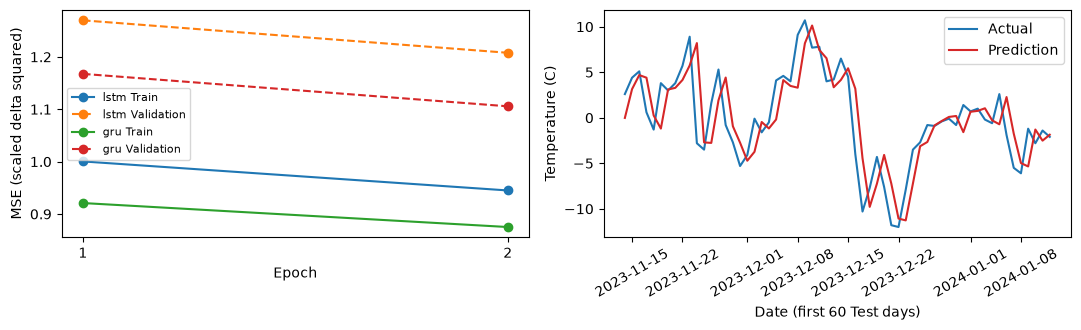

In [7]:
test_set = dataset.sets["test"]
prediction_scaled = predict(selected["model"], test_set.X)
prediction = dataset.reconstruct("test", prediction_scaled)
actual = dataset.actual("test")
naive_prediction = baselines.naive(prep.y, test_set.t)
residual = actual - prediction
display(pd.DataFrame({"actual (C)": actual[:5], "prediction (C)": prediction[:5],
                      "residual (C)": residual[:5], "absolute error (C)": np.abs(residual[:5])}))
display(pd.DataFrame({"Naive": regression_metrics(actual, naive_prediction, False),
                      selected["arch"]: regression_metrics(actual, prediction, False)}).T)
assert np.isclose(np.abs(residual).mean(), mae(actual, prediction))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for row in candidates:
    epochs = np.arange(1, 3)
    axes[0].plot(epochs, row["history"]["train_loss"], marker="o", label=row["arch"] + " Train")
    axes[0].plot(epochs, row["history"]["validation_loss"], marker="o", linestyle="--",
                 label=row["arch"] + " Validation")
axes[0].set(xlabel="Epoch", ylabel="MSE (scaled delta squared)", xticks=[1, 2])
axes[0].legend(fontsize=8)
axes[1].plot(prep.dates[test_set.t[:60]], actual[:60], label="Actual", color="tab:blue")
axes[1].plot(prep.dates[test_set.t[:60]], prediction[:60], label="Prediction", color="tab:red")
axes[1].set(xlabel="Date (first 60 Test days)", ylabel="Temperature (C)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()
fig.tight_layout()
plt.show()

왼쪽 실선/점선은 동일한 eval 조건의 Train/Validation MSE이며, ℃ MAE와는 단위가 다르다.
두 점만으로 과적합 추세를 확정하지 않는다. 오른쪽은 Test 처음 60일의 정답·예측이며 전체 점수는 위 표다.

## 6. 꽃 사진 한 장 → 클래스 번호 → 전처리
원본 Flowers 라벨(예: 4)은 이 과제의 target(예: 0)으로 다시 매핑된다.
행 정렬은 `target, order`이며 파일·정답·예측 순서를 함께 유지해야 한다.
다음 기본 추적은 클래스당 2장 Train, 앞 2장 Validation·Test의 **작은 별도 실험**이다.
캐시는 RGB 256×256 uint8이고, 평가 전처리는 Resize → CenterCrop → 0~1 → ImageNet 정규화다.
캐시를 만들 때 이미 가운데를 잘랐으므로 이후 해상도를 높여도 잃은 바깥 영역은 되살아나지 않는다.

In [8]:
from perfdiag.vision.data import CLASSES, class_names, load_manifest, load_split, ImageSet
from perfdiag.vision.models import TransferNet, count_parameters
from perfdiag.vision.train import (to_tensor, eval_transform, MEAN, STD, VisionConfig,
                                  fit as fit_vision, predict_proba, scores)
from torch.hub import get_dir
weights_path = Path(get_dir()) / "checkpoints/resnet18-f37072fd.pth"
if not (FLOWERS / "manifest.csv").exists() or not weights_path.exists():
    raise RuntimeError("README의 꽃 데이터·ResNet18 캐시 준비 후 다시 실행하세요")
weight_hash = hashlib.sha256(weights_path.read_bytes()).hexdigest()
assert weight_hash.startswith("f37072fd"), "사전학습 가중치 해시 확인 필요"
manifest = load_manifest()
names = class_names()
display(manifest[["label", "target", "class"]].drop_duplicates().sort_values("target"))
small_train = load_split(manifest, "train", shots=2)
small_validation = load_split(manifest, "validation", shots=22)
small_test = load_split(manifest, "test", shots=32)
first_image = small_train.images[:1]
tensor = to_tensor(first_image)
transformed = eval_transform(160)(tensor)
channel = 0
normalized_pixel = transformed[0, channel, 80, 80].item()
unit_pixel = normalized_pixel * STD[channel] + MEAN[channel]
print("NHWC cache:", first_image.shape, first_image.dtype, "→ NCHW:", tensor.shape)
print("model input:", transformed.shape, transformed.dtype)
print("center red: 0..1 =", unit_pixel, "; normalized =", normalized_pixel)
print("first target:", small_train.targets[0], names[small_train.targets[0]])
print("Train/Validation/Test small counts:", len(small_train.targets),
      len(small_validation.targets), len(small_test.targets))

,label,target,class
233,4,0,english marigold
54,11,1,colt's foot
376,46,2,marigold
141,49,3,common dandelion
504,53,4,sunflower
0,62,5,black-eyed susan
443,65,6,osteospermum
298,70,7,gazania


NHWC cache: (1, 256, 256, 3) uint8 → NCHW: torch.Size([1, 3, 256, 256])
model input: torch.Size([1, 3, 160, 160]) torch.float32
center red: 0..1 = 0.796078483581543 ; normalized = 1.3584213256835938
first target: 0 english marigold
Train/Validation/Test small counts: 16 16 16


## 7. pretrained 몸통 → 512개 특징 → 8개 점수
`requires_grad=False`는 가중치 미분을 끄고, `eval()`은 BatchNorm·Dropout의 동작을 바꾼다.
둘은 다른 상태다. linear_probe의 Train에서는 몸통 BatchNorm도 eval로 고정한다.
사전학습 몸통을 읽고 새 fc를 붙이며, 아래에서 forward = features → fc가 같은지 확인한다.
softmax는 점수(logit)를 합 1의 확률로 바꾸지만, 확률이 높다고 정답이거나 잘 보정됐다는 뜻은 아니다.

In [9]:
set_seed(0)
image_model = TransferNet(8, "linear_probe", dropout=0.1)
image_model.train()
print("trainable/total parameters:", count_parameters(image_model))
print("Train call → layer1 mode:", image_model.net.layer1.training,
      "; head mode:", image_model.net.fc.training)
assert not image_model.net.layer1.training and image_model.net.fc.training
image_model.eval()
with torch.no_grad():
    features = image_model.features(transformed)
    logits_from_parts = image_model.net.fc(features)
    logits = image_model(transformed)
    torch.testing.assert_close(logits_from_parts, logits)
    probability = torch.softmax(logits, dim=1)
print("features:", features.shape, "first 8 values:", features[0, :8].numpy())
display(pd.DataFrame({"class": names, "logit": logits[0].numpy(),
                      "probability": probability[0].numpy()}))
print("Before head training; predicted:", names[int(probability.argmax(1)[0])])

trainable/total parameters: (4104, 11180616)
Train call → layer1 mode: False ; head mode: True


features: torch.Size([1, 512]) first 8 values: [1.2418 0.3843 0.0796 1.2528 0.3955 2.6968 2.6826 0.6645]


,class,logit,probability
0,english marigold,-0.194149,0.106756
1,colt's foot,-1.131781,0.041801
2,marigold,1.243304,0.449441
3,common dandelion,-0.552913,0.074574
4,sunflower,-0.652769,0.067487
5,black-eyed susan,-1.480436,0.029496
6,osteospermum,-0.753335,0.061030
7,gazania,0.267656,0.169416


Before head training; predicted: marigold


## 8. 짧은 실제 학습과 오분류
16장으로 fc만 2 epoch 학습한다. `fit`은 Validation loss 최저 epoch를 복원하며 Test를 받지 않는다.
학습 후에도 얼린 몸통 가중치·BatchNorm 통계가 그대로인지 대조한다.
이 작은 실험은 높은 정확도를 목표로 하지 않는다. 오분류에 연결되는 배열 순서를 보는 것이 목표다.

best epoch: 2 small Test loss: 1.5779653787612915 accuracy: 0.5


,row,file,true,pred,confidence
0,6,common_dandelion/test_4947.jpg,common dandelion,colt's foot,0.587859
1,7,common_dandelion/test_4943.jpg,common dandelion,colt's foot,0.447832
2,8,sunflower/test_4384.jpg,sunflower,colt's foot,0.454516
3,9,sunflower/validation_0525.jpg,sunflower,colt's foot,0.407804
4,10,black-eyed_susan/test_4666.jpg,black-eyed susan,colt's foot,0.353185
5,11,black-eyed_susan/test_4687.jpg,black-eyed susan,colt's foot,0.405946
6,12,osteospermum/test_4462.jpg,osteospermum,colt's foot,0.338023
7,13,osteospermum/test_4482.jpg,osteospermum,colt's foot,0.275069


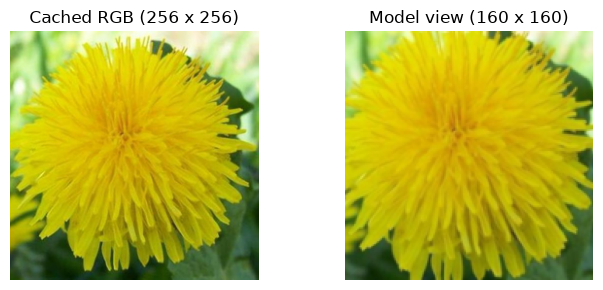

In [10]:
cfg = VisionConfig(strategy="linear_probe", epochs=2, batch_size=8, lr_head=0.01, seed=0)
set_seed(cfg.seed)
initial_model = TransferNet(8, cfg.strategy, cfg.dropout)
initial_body = initial_model.net.layer1[0].conv1.weight.detach().clone()
initial_bn = initial_model.net.bn1.running_mean.detach().clone()
trained_image_model, image_history = fit_vision(small_train, small_validation, cfg, 8, log=lambda *_: None)
torch.testing.assert_close(initial_body, trained_image_model.net.layer1[0].conv1.weight)
torch.testing.assert_close(initial_bn, trained_image_model.net.bn1.running_mean)
proba = predict_proba(trained_image_model, small_test.images, cfg.image_size)
predicted = proba.argmax(axis=1)
image_loss, image_error = scores(proba, small_test.targets)
print("best epoch:", image_history["best_epoch"], "small Test loss:", image_loss,
      "accuracy:", 1 - image_error)
error_rows = []
for i in range(len(predicted)):
    if predicted[i] != small_test.targets[i]:
        error_rows.append({"row": i, "file": small_test.files[i],
                           "true": names[small_test.targets[i]], "pred": names[predicted[i]],
                           "confidence": float(proba[i, predicted[i]])})
display(pd.DataFrame(error_rows))
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
show_row = error_rows[0]["row"] if error_rows else 0
axes[0].imshow(small_test.images[show_row])
axes[0].set_title("Cached RGB (256 x 256)")
axes[0].axis("off")
model_view = eval_transform(160)(to_tensor(small_test.images[show_row:show_row+1]))[0]
restored_rgb = model_view * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
axes[1].imshow(restored_rgb.permute(1, 2, 0).clamp(0, 1))
axes[1].set_title("Model view (160 x 160)")
axes[1].axis("off")
fig.tight_layout()
plt.show()

## 9. 오분류에서 관찰·가설·처방을 나누기
위 그림은 원본 전체가 아니라 캐시와 모델 입력이다. 꽃판 무늬, 가림, 배경을 관찰한 뒤
'유사한 꽃 구조 때문에 틀렸을 것'이라는 가설과 구분한다. 예측 한 장으로 배경 편향의 원인을 확정할 수 없다.
아래 표는 **기존 장기 실험의 태그 초안**이며 방금 작은 실험의 결과가 아니다.
확률은 해당 오분류를 뽑은 모델의 값이므로 작은 실험 확률과 섞지 않는다.

In [11]:
tags = pd.read_csv(ROOT / "annotations/error_tags.csv", dtype=str).fillna("")
print("tag columns:", tags.columns.tolist())
display(tags.head(3))
print("tag author counts:", tags["tagged_by"].value_counts().to_dict())
stored_improvement = json.loads((RESULTS / "vision_improve.json").read_text(encoding="utf-8"))
print("existing prescription:", stored_improvement["prescription"])
display(pd.DataFrame({"before": stored_improvement["before"], "after": stored_improvement["after"]}))

tag columns: ['no', 'file', 'true', 'pred', 'confidence', 'primary_tag', 'secondary_tags', 'detail', 'note', 'tagged_by', 'reviewed_by']


,no,file,true,pred,confidence,primary_tag,secondary_tags,detail,note,tagged_by,reviewed_by
0,1,english_marigold/test_4236.jpg,english marigold,sunflower,0.5437,클래스 유사성,배경/잡음,색·형태 유사;작은 객체·여러 송이,진한 주황 꽃잎과 짙은 갈색 꽃판이 해바라기의 어두운 꽃판과 닮았다. 뒤쪽에 다른 ...,claude-draft,
1,2,english_marigold/test_4230.jpg,english marigold,common dandelion,0.6247,클래스 유사성,데이터 품질,색·형태 유사;워터마크·글자,노란 기가 강한 금잔화라 민들레 색에 가깝다. 오른쪽 아래에 워터마크,claude-draft,
2,3,common_dandelion/train_0683.jpg,common dandelion,colt's foot,0.5989,배경/잡음,,배경 편향(흙·자갈·낙엽);객체 가림,전형적인 민들레인데 잔디가 아니라 자갈 위에 있다. 꿀벌이 꽃판 일부를 가린다,claude-draft,


tag author counts: {'claude-draft': 42}
existing prescription: deeper


,before,after
strategy,full,full
epochs,20,20
batch_size,16,16
lr_head,0.001,0.001
lr_backbone,0.0001,0.0001
weight_decay,0.0001,0.0001
dropout,0.0,0.0
augmentation,basic,basic
image_size,160,224
seed,0,0


'클래스 유사성' 태그가 많으면 높은 해상도로 미세 구조를 보게 하자는 가설을 세울 수 있다.
기존 full→full 처방에서는 동결 범위가 같고 160→224 해상도가 달라진다. 다른 전략에서는 학습 범위도 바뀔 수 있으므로 설정표를 확인한다.
비교할 때 데이터/분할/이미지 수/seed/epoch/증강/학습률을 맞추고 바뀐 요인을 밝힌다.
여러 요인이 함께 바뀌면 어느 하나의 효과라고 단정하지 않는다. seed 표준편차는 데이터 전체의 불확실성을 뜻하지 않는다.

태그는 사람이 사진과 참조 클래스를 보고 검수하기 전까지 초안이다. 이 노트북은 검수 완료 상태를 쓰지 않는다.
기존 Test 오분류를 보고 고른 처방은 같은 Test에서 확인한 **탐색적 개선**이다.
독립 효과를 주장하려면 처방을 고정한 뒤 별도의 미열람 데이터로 평가해야 한다.

## 친구에게 시연하기
1. t=3의 세 입력과 정답을 가리키고 Naive·SMA·잔차·MAE·RMSE를 계산한다.
2. 실제 첫 Validation target을 골라 fit 마지막 행, 입력 마지막 행, target 행을 구분한다.
3. 정규화된 0과 변화량 0이 왜 다른지, AAPL에서 exp가 왜 필요한지 말한다.
4. Train/Validation skill로 가설 하나를 정하고 Test를 본 뒤 다시 고르면 무엇이 달라지는지 설명한다.
5. 꽃 캐시→전처리→512 특징→8 점수→예측을 짚고 동결과 eval을 구분한다.
6. 오분류 한 장의 관찰·원인 가설·검증 실험을 각각 한 문장으로 말한다.

**확장 읽기**: `study/a6-2.html`은 기존 결과 비교, `scripts/ts_deep.py`는 장기 실험·선택,
`scripts/vision_improve.py`는 태그 기반 처방·seed 반복을 담당한다.
저장된 결과는 `tools/verify_learning_flow.py`로 현재 CSV·분할·예측·지표의 대응을 검사한다.
이 검사는 장기 학습 가중치를 다시 학습했다는 뜻은 아니다.